# River Water Quality Analysis

Statistical analysis of oxygen and nitrate concentrations (mg/L) in five river sections (A1 headwaters to A5 mouth) across four seasons, 900 measurements in total.

**Research questions**
1. Do oxygen and nitrate differ significantly between spring and autumn?
2. Do they differ between the five river sections, and which sections differ?


## Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from statsmodels.stats.multitest import multipletests
!pip install scikit-posthocs -q
import scikit_posthocs as sp_ph

plt.rcParams.update({"font.family": "serif", "font.serif": ["Times New Roman", "DejaVu Serif"], "font.size": 11})

## Step 1: Load and check the data

In [2]:
df = pd.read_csv("waterquality.csv", sep=";")
df.head(10)

,ID,river_section,saison,nitrate_mgL,oxygen_mgL
0,1,A1_headwaters,spring,5.540,10.711
1,2,A1_headwaters,spring,3.328,9.937
2,3,A1_headwaters,spring,5.742,10.499
3,4,A1_headwaters,spring,7.822,10.405
4,5,A1_headwaters,spring,8.843,10.245
5,6,A1_headwaters,spring,5.354,8.834
6,7,A1_headwaters,spring,5.614,9.596
7,8,A1_headwaters,spring,3.355,10.167
8,9,A1_headwaters,spring,6.690,8.906
9,10,A1_headwaters,spring,5.040,9.234


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 900 entries, 0 to 899
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   ID             900 non-null    int64  
 1   river_section  900 non-null    object 
 2   saison         900 non-null    object 
 3   nitrate_mgL    900 non-null    float64
 4   oxygen_mgL     900 non-null    float64
dtypes: float64(2), int64(1), object(2)
memory usage: 35.3+ KB


In [4]:
df.describe()

,ID,nitrate_mgL,oxygen_mgL
count,900.000000,900.000000,900.000000
mean,450.500000,8.811672,8.971169
std,259.951919,2.873274,1.425223
min,1.000000,1.510000,4.608000
25%,225.750000,6.762250,8.057500
50%,450.500000,8.887000,9.263500
75%,675.250000,10.926750,9.979000
max,900.000000,16.444000,12.167000


In [5]:
df.isna().sum()

,0
ID,0
river_section,0
saison,0
nitrate_mgL,0
oxygen_mgL,0


In [6]:
pd.crosstab(df["river_section"], df["saison"])

saison,autumn,spring,summer,winter
river_section,,,,
A1_headwaters,45,45,45,45
A2_upper_course,45,45,45,45
A3_middle_course,45,45,45,45
A4_lower_course,45,45,45,45
A5_mouth,45,45,45,45


In [7]:
df.groupby(["river_section", "saison"])["ID"].agg(["min", "max"])

min  max
river_section    saison          
A1_headwaters    autumn   91  135
                 spring    1   45
                 summer   46   90
                 winter  136  180
A2_upper_course  autumn  271  315
                 spring  181  225
                 summer  226  270
                 winter  316  360
A3_middle_course autumn  451  495
                 spring  361  405
                 summer  406  450
                 winter  496  540
A4_lower_course  autumn  631  675
                 spring  541  585
                 summer  586  630
                 winter  676  720
A5_mouth         autumn  811  855
                 spring  721  765
                 summer  766  810
                 winter  856  900

## Step 2: Descriptive statistics

In [8]:
season_order = ["spring", "summer", "autumn", "winter"]
section_order = ["A1_headwaters", "A2_upper_course", "A3_middle_course", "A4_lower_course", "A5_mouth"]
df["saison"] = pd.Categorical(df["saison"], categories=season_order, ordered=True)
df["river_section"] = pd.Categorical(df["river_section"], categories=section_order, ordered=True)

In [9]:
def summary(x):
    return pd.Series({
        "n": x.count(), "mean": x.mean(), "sd": x.std(),
        "min": x.min(), "Q1": x.quantile(0.25), "median": x.median(),
        "Q3": x.quantile(0.75), "max": x.max(),
        "IQR": x.quantile(0.75) - x.quantile(0.25)
    })

In [10]:
for var in ["nitrate_mgL", "oxygen_mgL"]:
    print(var)
    print(df.groupby("saison", observed=True)[var].apply(summary).unstack().round(2))

nitrate_mgL
            n   mean    sd   min    Q1  median     Q3    max   IQR
saison                                                            
spring  225.0   9.29  2.59  1.51  7.18    9.65  11.22  14.79  4.04
summer  225.0  10.34  2.74  3.96  8.36   10.71  12.52  16.44  4.17
autumn  225.0   8.42  2.75  2.00  6.63    8.57  10.51  16.38  3.88
winter  225.0   7.20  2.44  1.56  5.29    7.55   8.94  13.21  3.66
oxygen_mgL
            n  mean    sd   min    Q1  median     Q3    max   IQR
saison                                                           
spring  225.0  9.53  0.86  7.48  8.98    9.55  10.13  12.17  1.15
summer  225.0  7.04  0.93  4.61  6.35    6.98   7.76   9.81  1.41
autumn  225.0  9.38  0.89  6.61  8.74    9.51  10.01  12.11  1.26
winter  225.0  9.93  0.78  7.70  9.43    9.87  10.40  12.03  0.97


In [11]:
for var in ["nitrate_mgL", "oxygen_mgL"]:
    print(var)
    print(df.groupby("river_section", observed=True)[var].apply(summary).unstack().round(2))

nitrate_mgL
                      n   mean    sd   min     Q1  median     Q3    max   IQR
river_section                                                                
A1_headwaters     180.0   5.35  1.71  1.51   4.03    5.35   6.66  11.05  2.63
A2_upper_course   180.0   7.34  1.79  3.73   6.27    7.22   8.59  12.36  2.32
A3_middle_course  180.0   9.33  1.81  4.06   8.00    9.49  10.64  13.10  2.64
A4_lower_course   180.0  10.57  1.86  6.33   9.22   10.45  12.09  15.36  2.87
A5_mouth          180.0  11.47  1.98  6.64  10.17   11.40  13.01  16.44  2.85
oxygen_mgL
                      n  mean    sd   min    Q1  median     Q3    max   IQR
river_section                                                              
A1_headwaters     180.0  9.23  1.23  6.20  8.47    9.50  10.14  11.65  1.67
A2_upper_course   180.0  9.01  1.28  5.70  8.21    9.26   9.89  11.79  1.68
A3_middle_course  180.0  8.99  1.41  4.61  8.00    9.28  10.01  12.17  2.01
A4_lower_course   180.0  8.69  1.46  5.03  7.81    

In [12]:
desc = []
for col, order in [("saison", season_order), ("river_section", section_order)]:
    for g in order:
        sub = df[df[col] == g]
        desc.append([g, sub["nitrate_mgL"].mean(), sub["nitrate_mgL"].std(), sub["nitrate_mgL"].median(),
                     sub["oxygen_mgL"].mean(), sub["oxygen_mgL"].std(), sub["oxygen_mgL"].median()])
desc = pd.DataFrame(desc, columns=["Group", "N mean", "N sd", "N median", "O mean", "O sd", "O median"]).round(2)
print(desc.to_latex(index=False))

\begin{tabular}{lrrrrrr}
\toprule
Group & N mean & N sd & N median & O mean & O sd & O median \\
\midrule
spring & 9.290000 & 2.590000 & 9.650000 & 9.530000 & 0.860000 & 9.550000 \\
summer & 10.340000 & 2.740000 & 10.710000 & 7.040000 & 0.930000 & 6.980000 \\
autumn & 8.420000 & 2.750000 & 8.570000 & 9.380000 & 0.890000 & 9.510000 \\
winter & 7.200000 & 2.440000 & 7.550000 & 9.930000 & 0.780000 & 9.870000 \\
A1_headwaters & 5.350000 & 1.710000 & 5.350000 & 9.230000 & 1.230000 & 9.500000 \\
A2_upper_course & 7.340000 & 1.790000 & 7.220000 & 9.010000 & 1.280000 & 9.260000 \\
A3_middle_course & 9.330000 & 1.810000 & 9.490000 & 8.990000 & 1.410000 & 9.280000 \\
A4_lower_course & 10.570000 & 1.860000 & 10.450000 & 8.690000 & 1.460000 & 8.990000 \\
A5_mouth & 11.470000 & 1.980000 & 11.400000 & 8.940000 & 1.670000 & 9.420000 \\
\bottomrule
\end{tabular}



## Step 3: Graphics

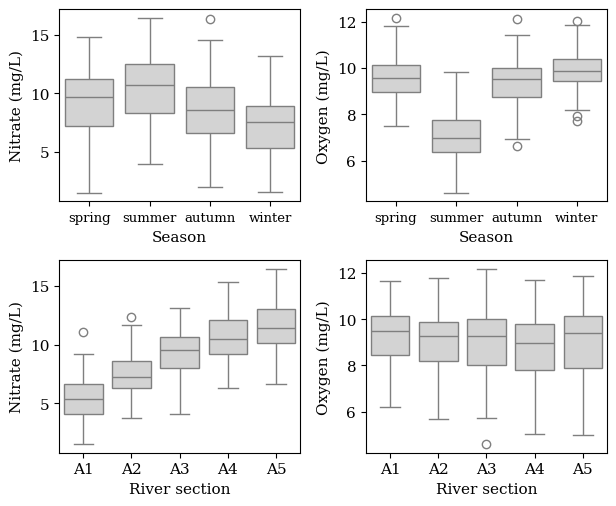

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(2, 2, figsize=(6.3, 5.2))

sns.boxplot(data=df, x="saison", y="nitrate_mgL", ax=axes[0, 0], color="lightgray")
sns.boxplot(data=df, x="saison", y="oxygen_mgL", ax=axes[0, 1], color="lightgray")
sns.boxplot(data=df, x="river_section", y="nitrate_mgL", ax=axes[1, 0], color="lightgray")
sns.boxplot(data=df, x="river_section", y="oxygen_mgL", ax=axes[1, 1], color="lightgray")

short = ["A1", "A2", "A3", "A4", "A5"]
for ax in axes[0]:
    ax.set_xlabel("Season")
    ax.tick_params(axis="x", labelsize=9.5)
for ax in axes[1]:
    ax.set_xticks(range(5))
    ax.set_xticklabels(short)
    ax.set_xlabel("River section")

axes[0, 0].set_ylabel("Nitrate (mg/L)")
axes[1, 0].set_ylabel("Nitrate (mg/L)")
axes[0, 1].set_ylabel("Oxygen (mg/L)")
axes[1, 1].set_ylabel("Oxygen (mg/L)")

plt.tight_layout()
plt.savefig("figure1_boxplots.png", dpi=300)
plt.show()

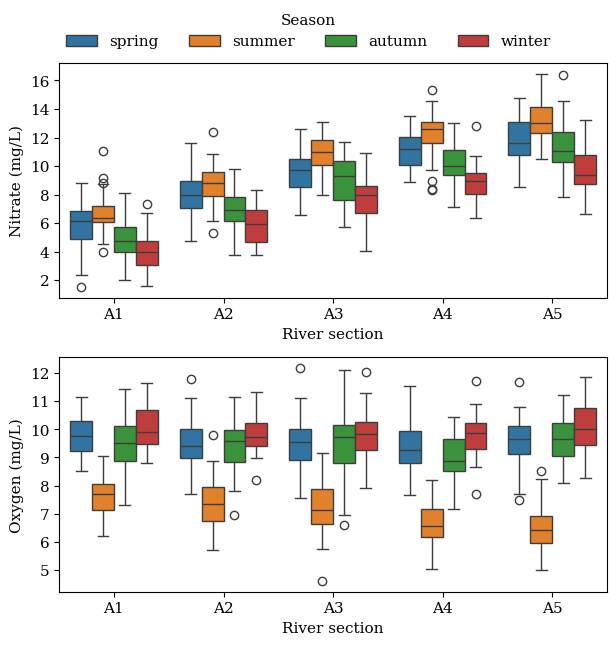

In [14]:
from matplotlib.ticker import MultipleLocator

fig, axes = plt.subplots(2, 1, figsize=(6.3, 6.5))

sns.boxplot(data=df, x="river_section", y="nitrate_mgL", hue="saison", ax=axes[0])
sns.boxplot(data=df, x="river_section", y="oxygen_mgL", hue="saison", ax=axes[1])

short = ["A1", "A2", "A3", "A4", "A5"]
for ax in axes:
    ax.set_xticks(range(5))
    ax.set_xticklabels(short)
    ax.set_xlabel("River section")
    ax.get_legend().remove()

axes[0].set_ylabel("Nitrate (mg/L)")
axes[1].set_ylabel("Oxygen (mg/L)")
axes[0].yaxis.set_major_locator(MultipleLocator(2))
axes[1].yaxis.set_major_locator(MultipleLocator(1))

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, title="Season", loc="upper center", ncol=4, frameon=False)

plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.savefig("figure2_section_by_season.png", dpi=300)
plt.show()

In [15]:
df[df["saison"]=="summer"].groupby("river_section", observed=True)["oxygen_mgL"].median()

,oxygen_mgL
river_section,
A1_headwaters,7.698
A2_upper_course,7.355
A3_middle_course,7.125
A4_lower_course,6.561
A5_mouth,6.416


## Step 4: Assumption checks (Shapiro–Wilk, Q–Q plots, Levene)

In [16]:
from scipy import stats

def shapiro_table(group_col, groups):
    rows = []
    for var in ["nitrate_mgL", "oxygen_mgL"]:
        for g in groups:
            x = df.loc[df[group_col] == g, var]
            W, p = stats.shapiro(x)
            rows.append([var, g, len(x), round(W, 4), round(p, 4)])
    return pd.DataFrame(rows, columns=["variable", "group", "n", "W", "p"])

print("Seasons (Question 1)")
print(shapiro_table("saison", ["spring", "autumn"]))
print("\nRiver sections (Question 2)")
print(shapiro_table("river_section", section_order))

Seasons (Question 1)
      variable   group    n       W       p
0  nitrate_mgL  spring  225  0.9854  0.0206
1  nitrate_mgL  autumn  225  0.9850  0.0179
2   oxygen_mgL  spring  225  0.9940  0.5144
3   oxygen_mgL  autumn  225  0.9892  0.0891

River sections (Question 2)
      variable             group    n       W       p
0  nitrate_mgL     A1_headwaters  180  0.9896  0.2129
1  nitrate_mgL   A2_upper_course  180  0.9878  0.1226
2  nitrate_mgL  A3_middle_course  180  0.9865  0.0822
3  nitrate_mgL   A4_lower_course  180  0.9881  0.1368
4  nitrate_mgL          A5_mouth  180  0.9910  0.3246
5   oxygen_mgL     A1_headwaters  180  0.9725  0.0013
6   oxygen_mgL   A2_upper_course  180  0.9601  0.0001
7   oxygen_mgL  A3_middle_course  180  0.9678  0.0004
8   oxygen_mgL   A4_lower_course  180  0.9530  0.0000
9   oxygen_mgL          A5_mouth  180  0.9310  0.0000


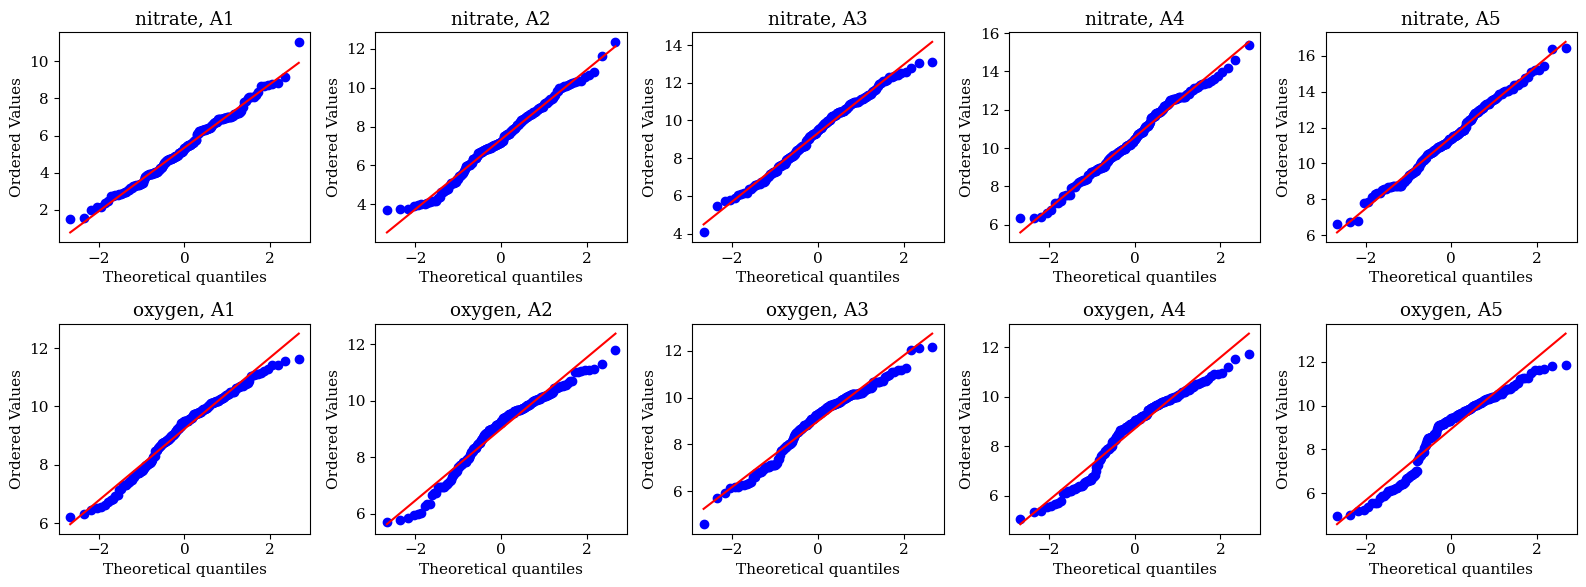

In [17]:
fig, axes = plt.subplots(2, 5, figsize=(16, 6))
for i, var in enumerate(["nitrate_mgL", "oxygen_mgL"]):
    for j, g in enumerate(section_order):
        stats.probplot(df.loc[df["river_section"] == g, var], dist="norm", plot=axes[i, j])
        axes[i, j].set_title(f"{var.split('_')[0]}, {g.split('_')[0]}")
plt.tight_layout()
plt.savefig("qq_sections.png", dpi=200)
plt.show()

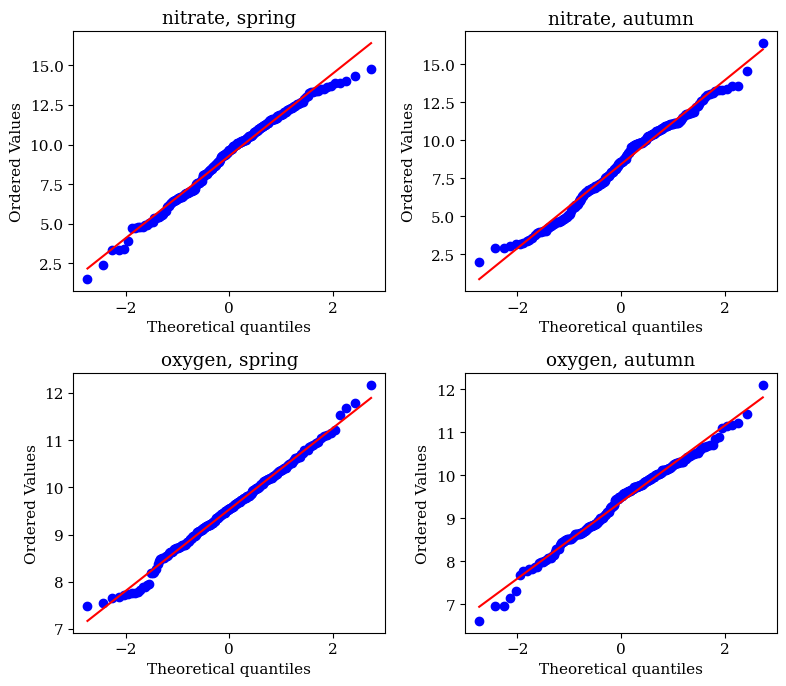

In [18]:
fig, axes = plt.subplots(2, 2, figsize=(8, 7))
for i, var in enumerate(["nitrate_mgL", "oxygen_mgL"]):
    for j, s in enumerate(["spring", "autumn"]):
        stats.probplot(df.loc[df["saison"] == s, var], dist="norm", plot=axes[i, j])
        axes[i, j].set_title(f"{var.split('_')[0]}, {s}")
plt.tight_layout()
plt.savefig("qq_seasons.png", dpi=200)
plt.show()

In [19]:
for var in ["nitrate_mgL", "oxygen_mgL"]:
    sp = df.loc[df["saison"] == "spring", var]
    au = df.loc[df["saison"] == "autumn", var]
    print(var, "spring vs autumn:", stats.levene(sp, au, center="median"))
    groups = [df.loc[df["river_section"] == g, var] for g in section_order]
    print(var, "5 sections:", stats.levene(*groups, center="median"))

nitrate_mgL spring vs autumn: LeveneResult(statistic=np.float64(1.5601062573063793), pvalue=np.float64(0.2123018987929969))
nitrate_mgL 5 sections: LeveneResult(statistic=np.float64(1.0973749342114285), pvalue=np.float64(0.35656630885357216))
oxygen_mgL spring vs autumn: LeveneResult(statistic=np.float64(0.6629190600535767), pvalue=np.float64(0.4159638518950779))
oxygen_mgL 5 sections: LeveneResult(statistic=np.float64(3.1972105460597557), pvalue=np.float64(0.012769474218993973))


## Step 5: Spring vs. autumn (Welch's t-test, Mann–Whitney U, Holm)

In [20]:
import numpy as np

results = []
for var in ["nitrate_mgL", "oxygen_mgL"]:
    sp = df.loc[df["saison"] == "spring", var]
    au = df.loc[df["saison"] == "autumn", var]

    t, p_t = stats.ttest_ind(sp, au, equal_var=False)          # Welch
    U, p_u = stats.mannwhitneyu(sp, au, alternative="two-sided")  # robustness check

    diff = sp.mean() - au.mean()
    se = np.sqrt(sp.var(ddof=1)/len(sp) + au.var(ddof=1)/len(au))
    dof = se**4 / ((sp.var(ddof=1)/len(sp))**2/(len(sp)-1) + (au.var(ddof=1)/len(au))**2/(len(au)-1))
    ci = (diff - stats.t.ppf(0.975, dof)*se, diff + stats.t.ppf(0.975, dof)*se)
    d = diff / np.sqrt((sp.var(ddof=1) + au.var(ddof=1)) / 2)  # Cohen's d

    results.append([var, round(diff, 3), round(ci[0], 3), round(ci[1], 3), round(t, 3),
                    round(dof, 1), p_t, round(d, 3), p_u])

res = pd.DataFrame(results, columns=["variable", "mean diff (spring-autumn)", "CI low", "CI high",
                                     "t", "df", "p Welch", "Cohen d", "p Mann-Whitney"])
print(res)

      variable  mean diff (spring-autumn)  CI low  CI high      t     df  \
0  nitrate_mgL                      0.871   0.375    1.366  3.455  446.4   
1   oxygen_mgL                      0.152  -0.010    0.314  1.847  447.4   

    p Welch  Cohen d  p Mann-Whitney  
0  0.000602    0.326        0.000780  
1  0.065407    0.174        0.126633  


In [21]:
from statsmodels.stats.multitest import multipletests
reject, p_holm, _, _ = multipletests(res["p Welch"], alpha=0.05, method="holm")
res["p Welch (Holm)"] = p_holm
res["significant"] = reject
print(res[["variable", "p Welch", "p Welch (Holm)", "significant"]])

      variable   p Welch  p Welch (Holm)  significant
0  nitrate_mgL  0.000602        0.001205         True
1   oxygen_mgL  0.065407        0.065407        False


## Step 6: River sections (ANOVA + Tukey for nitrate, Kruskal–Wallis + Dunn for oxygen)

In [22]:
from statsmodels.stats.multicomp import pairwise_tukeyhsd

groups_n = [df.loc[df["river_section"] == g, "nitrate_mgL"] for g in section_order]
F, p_anova = stats.f_oneway(*groups_n)

grand = df["nitrate_mgL"].mean()
ss_between = sum(len(g) * (g.mean() - grand)**2 for g in groups_n)
ss_total = ((df["nitrate_mgL"] - grand)**2).sum()
eta2 = ss_between / ss_total
print(f"ANOVA nitrate: F(4, 895) = {F:.2f}, p = {p_anova:.3e}, eta^2 = {eta2:.3f}")

tukey = pairwise_tukeyhsd(df["nitrate_mgL"], df["river_section"].astype(str), alpha=0.05)
print(tukey.summary())

ANOVA nitrate: F(4, 895) = 329.10, p = 4.246e-174, eta^2 = 0.595
         Multiple Comparison of Means - Tukey HSD, FWER=0.05         
     group1           group2      meandiff p-adj lower  upper  reject
---------------------------------------------------------------------
   A1_headwaters  A2_upper_course   1.9925   0.0 1.4647 2.5204   True
   A1_headwaters A3_middle_course    3.978   0.0 3.4502 4.5058   True
   A1_headwaters  A4_lower_course   5.2196   0.0 4.6918 5.7475   True
   A1_headwaters         A5_mouth   6.1162   0.0 5.5884  6.644   True
 A2_upper_course A3_middle_course   1.9855   0.0 1.4576 2.5133   True
 A2_upper_course  A4_lower_course   3.2271   0.0 2.6993 3.7549   True
 A2_upper_course         A5_mouth   4.1236   0.0 3.5958 4.6515   True
A3_middle_course  A4_lower_course   1.2416   0.0 0.7138 1.7695   True
A3_middle_course         A5_mouth   2.1382   0.0 1.6103  2.666   True
 A4_lower_course         A5_mouth   0.8965   0.0 0.3687 1.4244   True
-------------------------

In [23]:
print(tukey.pvalues)

[1.19237953e-13 1.19237953e-13 1.19237953e-13 1.19237953e-13
 1.19237953e-13 1.19237953e-13 1.19237953e-13 2.07603990e-09
 1.19237953e-13 3.88458034e-05]


In [24]:
groups_o = [df.loc[df["river_section"] == g, "oxygen_mgL"] for g in section_order]
H, p_kw = stats.kruskal(*groups_o)
n, k = len(df), 5
eta2_H = (H - k + 1) / (n - k)   # eta-squared_H effect size
print(f"Kruskal-Wallis oxygen: H(4) = {H:.2f}, p = {p_kw:.3e}, eta^2_H = {eta2_H:.3f}")

dunn = sp_ph.posthoc_dunn(df, val_col="oxygen_mgL", group_col="river_section", p_adjust="holm")
print(dunn.round(4))

Kruskal-Wallis oxygen: H(4) = 11.65, p = 2.019e-02, eta^2_H = 0.009
                  A1_headwaters  A2_upper_course  A3_middle_course  \
A1_headwaters            1.0000           0.7048            0.7276   
A2_upper_course          0.7048           1.0000            1.0000   
A3_middle_course         0.7276           1.0000            1.0000   
A4_lower_course          0.0079           0.5151            0.4604   
A5_mouth                 1.0000           1.0000            1.0000   

                  A4_lower_course  A5_mouth  
A1_headwaters              0.0079    1.0000  
A2_upper_course            0.5151    1.0000  
A3_middle_course           0.4604    1.0000  
A4_lower_course            1.0000    0.2437  
A5_mouth                   0.2437    1.0000  


In [25]:
_, p_glob, _, _ = multipletests([p_anova, p_kw], method="holm")
print("Holm-adjusted global p-values (nitrate ANOVA, oxygen KW):", p_glob)

Holm-adjusted global p-values (nitrate ANOVA, oxygen KW): [8.49285029e-174 2.01949605e-002]


## Software versions

In [26]:
import sys, scipy, statsmodels, matplotlib, seaborn, scikit_posthocs
print("Python", sys.version.split()[0])
for m in [pd, np, scipy, statsmodels, matplotlib, seaborn, scikit_posthocs]:
    print(m.__name__, m.__version__)

Python 3.13.18
pandas 2.2.3
numpy 2.4.6
scipy 1.16.3
statsmodels 0.15.0
matplotlib 3.10.0
seaborn 0.13.2
scikit_posthocs 0.18.0
